In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# Load and understand the dataset

In [2]:
# Load the CSV file
df = pd.read_csv(r"D:\btech\Sem - 5\IT 340M\Patient_Risk_Stratification_Project\Data\diabetes_binary_health_indicators_BRFSS2015.csv")

# Display the first five rows
df.head()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 253680
Number of columns: 22


In [4]:
print(df.columns.tolist())

['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

In [6]:
df.describe()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
count,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,...,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000
mean,0.139333,0.429001,0.424121,0.962670,28.382364,0.443169,0.040571,0.094186,0.756544,0.634256,...,0.951053,0.084177,2.511392,3.184772,4.242081,0.168224,0.440342,8.032119,5.050434,6.053875
std,0.346294,0.494934,0.494210,0.189571,6.608694,0.496761,0.197294,0.292087,0.429169,0.481639,...,0.215759,0.277654,1.068477,7.412847,8.717951,0.374066,0.496429,3.054220,0.985774,2.071148
min,0.000000,0.000000,0.000000,0.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,1.000000,24.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,6.000000,4.000000,5.000000
50%,0.000000,0.000000,0.000000,1.000000,27.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,8.000000,5.000000,7.000000
75%,0.000000,1.000000,1.000000,1.000000,31.000000,1.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,1.000000,10.000000,6.000000,8.000000
max,1.000000,1.000000,1.000000,1.000000,98.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,5.000000,30.000000,30.000000,1.000000,1.000000,13.000000,6.000000,8.000000


In [7]:
df["Diabetes_binary"].value_counts()

Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

In [8]:
df["Diabetes_binary"].value_counts(normalize=True) * 100

Diabetes_binary
0.0    86.066698
1.0    13.933302
Name: proportion, dtype: float64

# Exploratory Data Analysis (EDA)

In [9]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Display columns with missing values
print(missing_values)

Diabetes_binary         0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64


In [10]:
df[df.duplicated()]

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
1242,1.0,1.0,1.0,1.0,27.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,0.0,30.0,1.0,0.0,10.0,4.0,5.0
1563,0.0,0.0,0.0,1.0,21.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,4.0,6.0,8.0
2700,0.0,0.0,0.0,1.0,32.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,5.0,6.0,8.0
3160,0.0,0.0,0.0,1.0,21.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,4.0,6.0,8.0
3332,0.0,0.0,0.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,9.0,6.0,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
253492,1.0,1.0,1.0,1.0,33.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,9.0,6.0,6.0
253550,0.0,0.0,0.0,1.0,25.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,7.0,6.0,8.0
253563,0.0,0.0,1.0,1.0,24.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,1.0,8.0,6.0,8.0
253597,0.0,0.0,0.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,5.0,6.0,8.0


In [11]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 24206


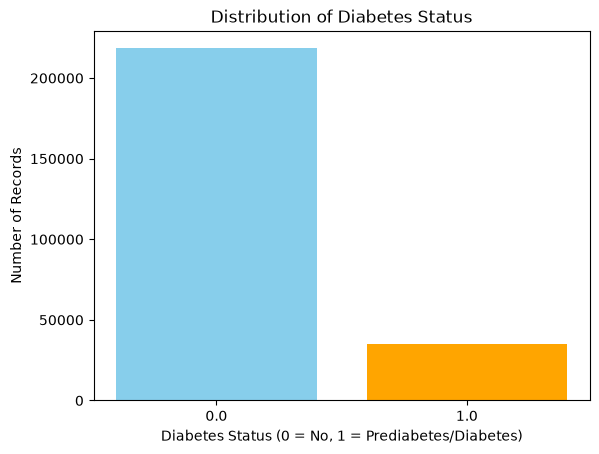

In [12]:
# Count the occurrences of each category
counts = df["Diabetes_binary"].value_counts()

# Plot the counts as a bar chart
plt.bar(counts.index.astype(str), counts.values, color=["skyblue", "orange"])

plt.title("Distribution of Diabetes Status")
plt.xlabel("Diabetes Status (0 = No, 1 = Prediabetes/Diabetes)")
plt.ylabel("Number of Records")
plt.show()

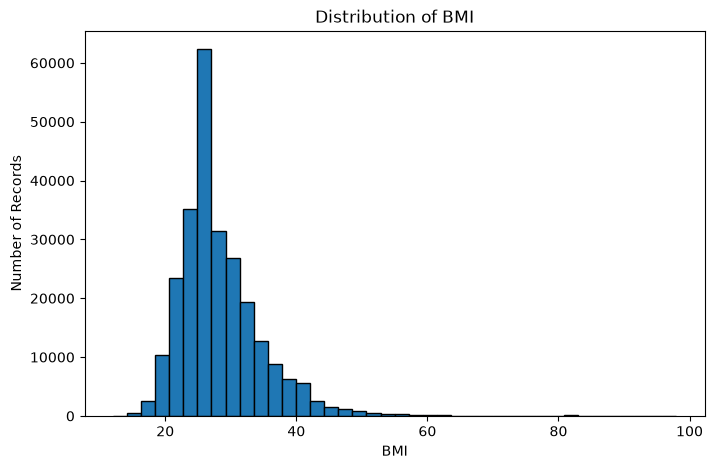

In [13]:
# BMI distribution
plt.figure(figsize=(8, 5))

plt.hist(x=df["BMI"], bins=40, edgecolor="black")

plt.title("Distribution of BMI")
plt.xlabel("BMI")
plt.ylabel("Number of Records")

plt.show()

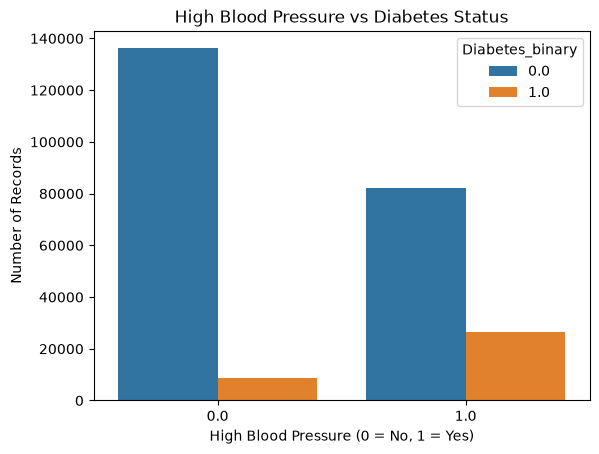

In [14]:
# High blood pressure versus target
sns.countplot(
    data=df,
    x="HighBP",
    hue="Diabetes_binary"
)

plt.title("High Blood Pressure vs Diabetes Status")
plt.xlabel("High Blood Pressure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")

plt.show()

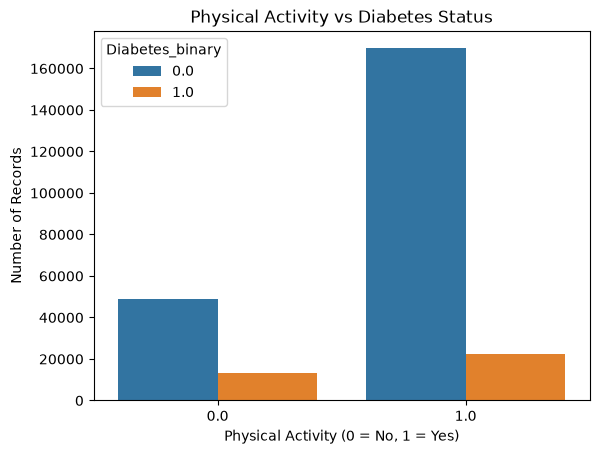

In [15]:
# Physical activity versus target
sns.countplot(
    data=df,
    x="PhysActivity",
    hue="Diabetes_binary"
)

plt.title("Physical Activity vs Diabetes Status")
plt.xlabel("Physical Activity (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")

plt.show()

In [16]:
# Correlation with the target
correlations = (
    df.corr(numeric_only=True)["Diabetes_binary"]
    .drop("Diabetes_binary")
    .sort_values(ascending=False)
)

print(correlations)

GenHlth                 0.293569
HighBP                  0.263129
DiffWalk                0.218344
BMI                     0.216843
HighChol                0.200276
Age                     0.177442
HeartDiseaseorAttack    0.177282
PhysHlth                0.171337
Stroke                  0.105816
MentHlth                0.069315
CholCheck               0.064761
Smoker                  0.060789
NoDocbcCost             0.031433
Sex                     0.031430
AnyHealthcare           0.016255
Fruits                 -0.040779
Veggies                -0.056584
HvyAlcoholConsump      -0.057056
PhysActivity           -0.118133
Education              -0.124456
Income                 -0.163919
Name: Diabetes_binary, dtype: float64


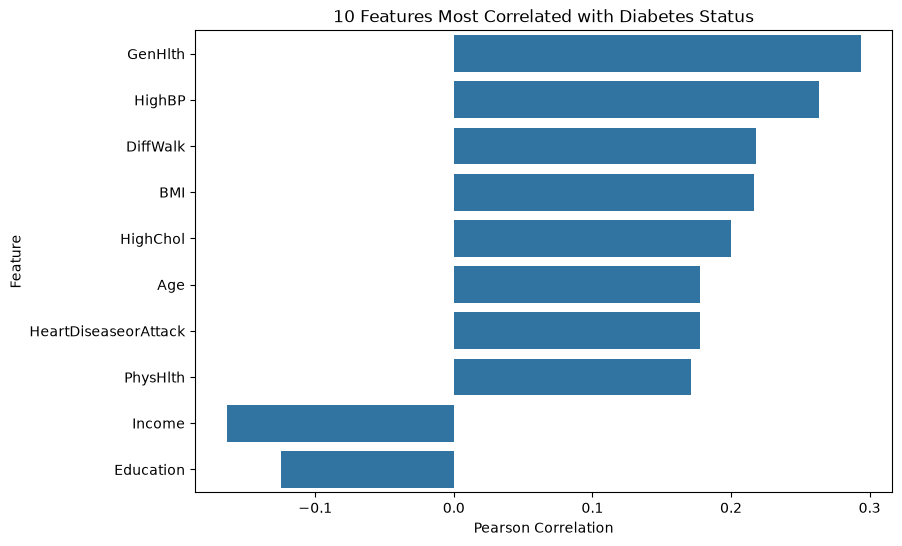

In [17]:
# Plot the strongest correlations
top_correlations = correlations.abs().sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(9, 6))

sns.barplot(
    x=correlations.loc[top_correlations.index].values,
    y=top_correlations.index
)

plt.title("10 Features Most Correlated with Diabetes Status")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")

plt.show()

In [18]:
correlation_matrix = df.corr()

correlation_matrix.round(2)

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
Diabetes_binary,1.00,0.26,0.20,0.06,0.22,0.06,0.11,0.18,-0.12,-0.04,...,0.02,0.03,0.29,0.07,0.17,0.22,0.03,0.18,-0.12,-0.16
HighBP,0.26,1.00,0.30,0.10,0.21,0.10,0.13,0.21,-0.13,-0.04,...,0.04,0.02,0.30,0.06,0.16,0.22,0.05,0.34,-0.14,-0.17
HighChol,0.20,0.30,1.00,0.09,0.11,0.09,0.09,0.18,-0.08,-0.04,...,0.04,0.01,0.21,0.06,0.12,0.14,0.03,0.27,-0.07,-0.09
CholCheck,0.06,0.10,0.09,1.00,0.03,-0.01,0.02,0.04,0.00,0.02,...,0.12,-0.06,0.05,-0.01,0.03,0.04,-0.02,0.09,0.00,0.01
BMI,0.22,0.21,0.11,0.03,1.00,0.01,0.02,0.05,-0.15,-0.09,...,-0.02,0.06,0.24,0.09,0.12,0.20,0.04,-0.04,-0.10,-0.10
Smoker,0.06,0.10,0.09,-0.01,0.01,1.00,0.06,0.11,-0.09,-0.08,...,-0.02,0.05,0.16,0.09,0.12,0.12,0.09,0.12,-0.16,-0.12
Stroke,0.11,0.13,0.09,0.02,0.02,0.06,1.00,0.20,-0.07,-0.01,...,0.01,0.03,0.18,0.07,0.15,0.18,0.00,0.13,-0.08,-0.13
HeartDiseaseorAttack,0.18,0.21,0.18,0.04,0.05,0.11,0.20,1.00,-0.09,-0.02,...,0.02,0.03,0.26,0.06,0.18,0.21,0.09,0.22,-0.10,-0.14
PhysActivity,-0.12,-0.13,-0.08,0.00,-0.15,-0.09,-0.07,-0.09,1.00,0.14,...,0.04,-0.06,-0.27,-0.13,-0.22,-0.25,0.03,-0.09,0.20,0.20
Fruits,-0.04,-0.04,-0.04,0.02,-0.09,-0.08,-0.01,-0.02,0.14,1.00,...,0.03,-0.04,-0.10,-0.07,-0.04,-0.05,-0.09,0.06,0.11,0.08


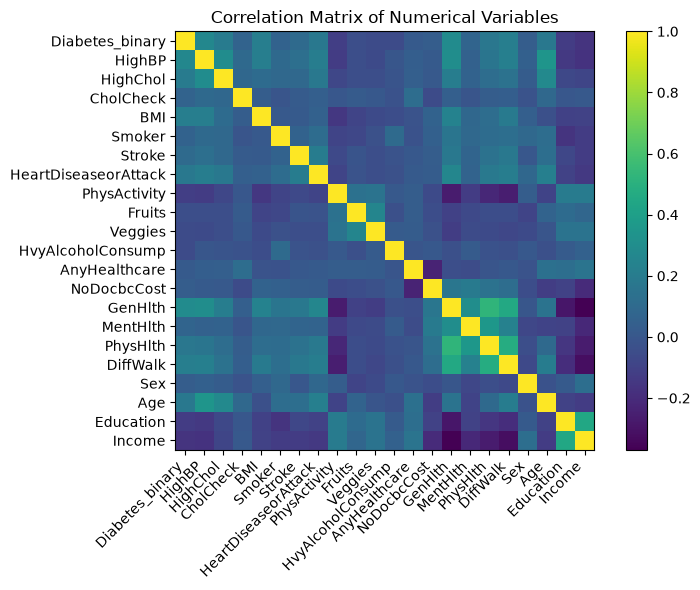

In [19]:
fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(correlation_matrix)

ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.columns)))

ax.set_xticklabels(
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(correlation_matrix.columns)

plt.colorbar(im)

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()

plt.show()

# Data preprocessing and train/test splitting

In [20]:
# Target variable
target = "Diabetes_binary"

# Input features
X = df.drop(columns=[target])

# Output labels
y = df[target]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (253680, 21)
Target shape: (253680,)


In [21]:
# Calculate class percentages
class_counts = y.value_counts().sort_index()
class_percentages = y.value_counts(
    normalize=True
).sort_index() * 100

print("Class counts:")
print(class_counts)

print("\nClass percentages:")
print(class_percentages)

Class counts:
Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

Class percentages:
Diabetes_binary
0.0    86.066698
1.0    13.933302
Name: proportion, dtype: float64


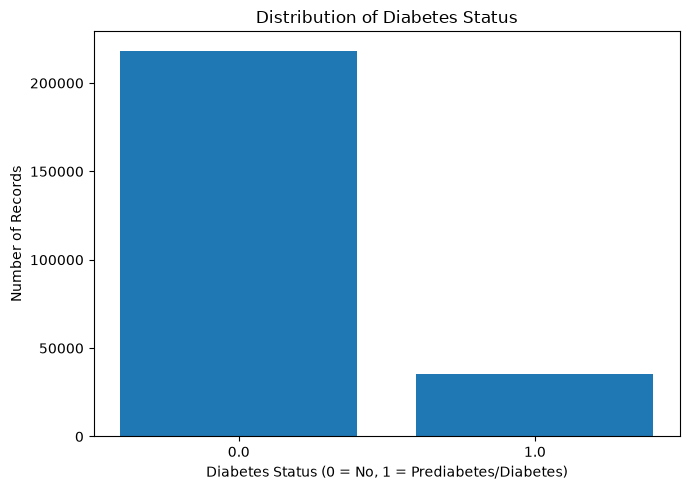

In [22]:
# Plot the class distribution
plt.figure(figsize=(7, 5))

plt.bar(
    class_counts.index.astype(str),
    class_counts.values
)

plt.title("Distribution of Diabetes Status")
plt.xlabel("Diabetes Status (0 = No, 1 = Prediabetes/Diabetes)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

In [23]:
# Train test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (202944, 21)
Testing features: (50736, 21)
Training target: (202944,)
Testing target: (50736,)


In [24]:
# Compare class proportions
print("Original dataset:")
print((y.value_counts(normalize=True) * 100).sort_index())

print("\nTraining set:")
print((y_train.value_counts(normalize=True) * 100).sort_index())

print("\nTesting set:")
print((y_test.value_counts(normalize=True) * 100).sort_index())

Original dataset:
Diabetes_binary
0.0    86.066698
1.0    13.933302
Name: proportion, dtype: float64

Training set:
Diabetes_binary
0.0    86.0666
1.0    13.9334
Name: proportion, dtype: float64

Testing set:
Diabetes_binary
0.0    86.067092
1.0    13.932908
Name: proportion, dtype: float64


# first ML model: Logistic Regression

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# standardization
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Create the model
logistic_model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [26]:
# Generate predictions
y_pred = logistic_model.predict(X_test)

# Estimated probability of class 1
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("First 10 actual labels:")
print(y_test.iloc[:10].to_list())

print("\nFirst 10 predicted labels:")
print(y_pred[:10])

print("\nFirst 10 predicted probabilities:")
print(y_prob[:10])

First 10 actual labels:
[0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]

First 10 predicted labels:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

First 10 predicted probabilities:
[0.15379378 0.29301082 0.02002913 0.03335854 0.48138713 0.11825813
 0.0287279  0.01087996 0.05332022 0.16678802]


In [27]:
# Evaluate the model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nDetailed classification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.8621
Precision: 0.5171
Recall   : 0.1583
F1-score : 0.2424
ROC-AUC  : 0.8192

Detailed classification report:
              precision    recall  f1-score   support

         0.0       0.88      0.98      0.92     43667
         1.0       0.52      0.16      0.24      7069

    accuracy                           0.86     50736
   macro avg       0.70      0.57      0.58     50736
weighted avg       0.83      0.86      0.83     50736



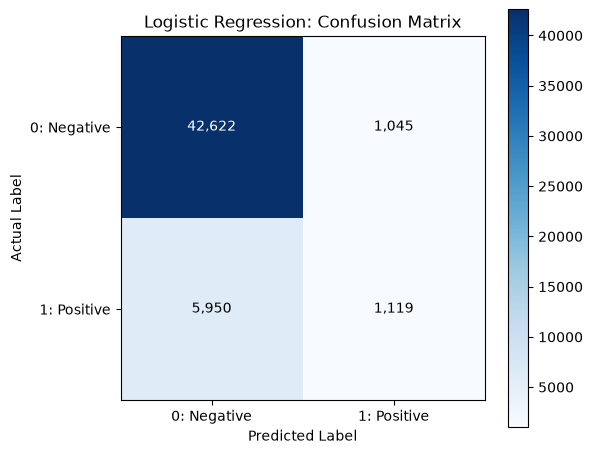

In [28]:
# Plot the confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(6, 5))

image = ax.imshow(cm, interpolation="nearest", cmap="Blues")
fig.colorbar(image, ax=ax)

ax.set(
    title="Logistic Regression: Confusion Matrix",
    xlabel="Predicted Label",
    ylabel="Actual Label",
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=["0: Negative", "1: Positive"],
    yticklabels=["0: Negative", "1: Positive"]
)

# Display the count in each cell
threshold = cm.max() / 2

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, f"{cm[i, j]:,}",
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

plt.tight_layout()
plt.show()

### Improve the model using class weights

In [29]:
# Train a class-weighted model
weighted_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

### Select a decision threshold without using the test set

In [30]:
# Create a validation set
from sklearn.model_selection import train_test_split

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

validation_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

validation_model.fit(X_subtrain, y_subtrain)

val_prob = validation_model.predict_proba(X_val)[:, 1]

print("Validation set:", X_val.shape)

Validation set: (40589, 21)


In [31]:
# Compare thresholds
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60]

results = []

for threshold in thresholds:
    val_pred = (val_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, val_pred, zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)
print(threshold_results.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-score
       0.2     0.2035  0.9645    0.3361
       0.3     0.2395  0.9204    0.3801
       0.4     0.2738  0.8520    0.4145
       0.5     0.3107  0.7613    0.4412
       0.6     0.3539  0.6481    0.4578


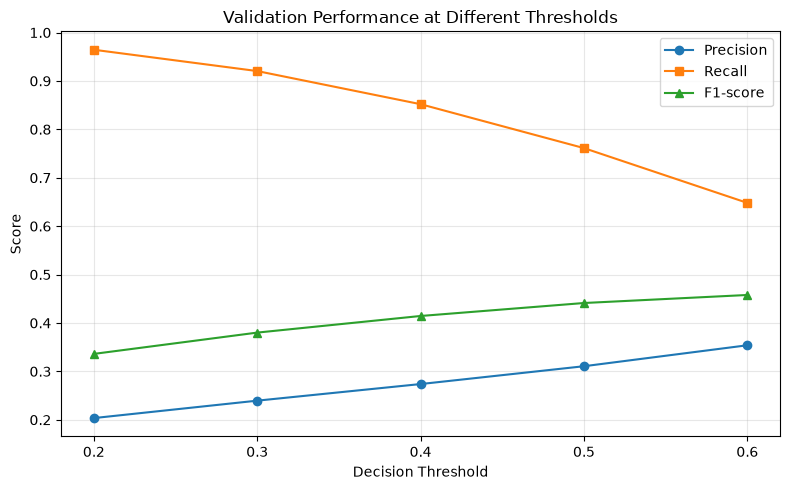

In [32]:
# Visualize the threshold trade-off with Matplotlib
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="s",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1-score"],
    marker="^",
    label="F1-score"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Validation Performance at Different Thresholds")
plt.xticks(thresholds)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [33]:
# Train the final class-weighted model
weighted_model.fit(X_train, y_train)

print("Final class-weighted model trained.")

Final class-weighted model trained.


In [34]:
# Estimated probabilities from the final model
test_prob = weighted_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data
chosen_threshold = 0.60
weighted_pred = (test_prob >= chosen_threshold).astype(int)

print("Accuracy :", round(accuracy_score(y_test, weighted_pred), 4))
print("Precision:", round(precision_score(y_test, weighted_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, weighted_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, weighted_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, test_prob), 4))

print("\nClassification report:")
print(classification_report(y_test, weighted_pred, zero_division=0))

Accuracy : 0.7864
Precision: 0.3545
Recall   : 0.6492
F1-score : 0.4586
ROC-AUC  : 0.8196

Classification report:
              precision    recall  f1-score   support

         0.0       0.93      0.81      0.87     43667
         1.0       0.35      0.65      0.46      7069

    accuracy                           0.79     50736
   macro avg       0.64      0.73      0.66     50736
weighted avg       0.85      0.79      0.81     50736



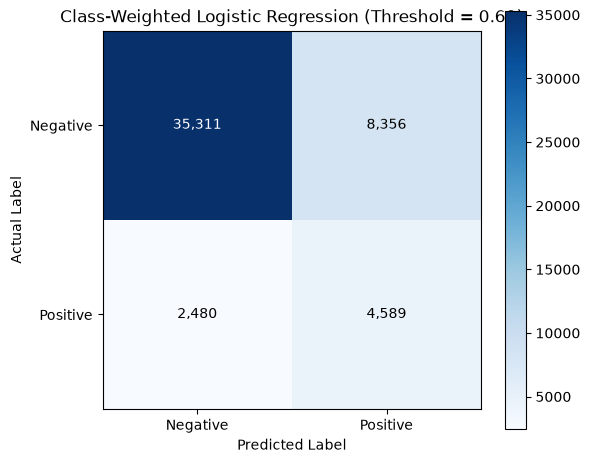

In [35]:
# Plot the new confusion matrix
cm = confusion_matrix(y_test, weighted_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(cm, cmap="Blues")
fig.colorbar(im, ax=ax)

ax.set_title("Class-Weighted Logistic Regression (Threshold = 0.60)")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")
ax.set_xticks([0, 1], ["Negative", "Positive"])
ax.set_yticks([0, 1], ["Negative", "Positive"])

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, f"{cm[i, j]:,}",
            ha="center",
            va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black"
        )

plt.tight_layout()
plt.show()

In [36]:
# Compare the original and improved models
# Original model predictions
baseline_pred = logistic_model.predict(X_test)
baseline_prob = logistic_model.predict_proba(X_test)[:, 1]

def evaluate_model(name, y_true, predictions, probabilities):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

comparison = pd.DataFrame([
    evaluate_model(
        "Original Logistic Regression (0.50)",
        y_test, baseline_pred, baseline_prob
    ),
    evaluate_model(
        "Class-Weighted Logistic Regression (0.60)",
        y_test, weighted_pred, test_prob
    )
])

print(comparison.round(4).to_string(index=False))

                                    Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
      Original Logistic Regression (0.50)    0.8621     0.5171  0.1583    0.2424   0.8192
Class-Weighted Logistic Regression (0.60)    0.7864     0.3545  0.6492    0.4586   0.8196


## Train Decision Tree and Random Forest

In [37]:
# Train a Decision Tree
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=10,
    min_samples_leaf=100,
    random_state=42
)

tree_model.fit(X_train, y_train)

print("Decision Tree training completed.")

Decision Tree training completed.


In [38]:
# Train a Random Forest
from sklearn.ensemble import RandomForestClassifier

forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=50,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

forest_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [39]:
# Generate predictions and calculate metrics
def evaluate_model(name, model, X_test, y_test):
    # Predicted class labels
    predictions = model.predict(X_test)

    # Estimated probability of the positive class
    probabilities = model.predict_proba(X_test)[:, 1]

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

results = pd.DataFrame([
    evaluate_model(
        "Logistic Regression",
        logistic_model, X_test, y_test
    ),
    evaluate_model(
        "Decision Tree",
        tree_model, X_test, y_test
    ),
    evaluate_model(
        "Random Forest",
        forest_model, X_test, y_test
    )
])

print(results.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
Logistic Regression    0.8621     0.5171  0.1583    0.2424   0.8192
      Decision Tree    0.7133     0.2969  0.7728    0.4290   0.8140
      Random Forest    0.7222     0.3061  0.7843    0.4403   0.8237


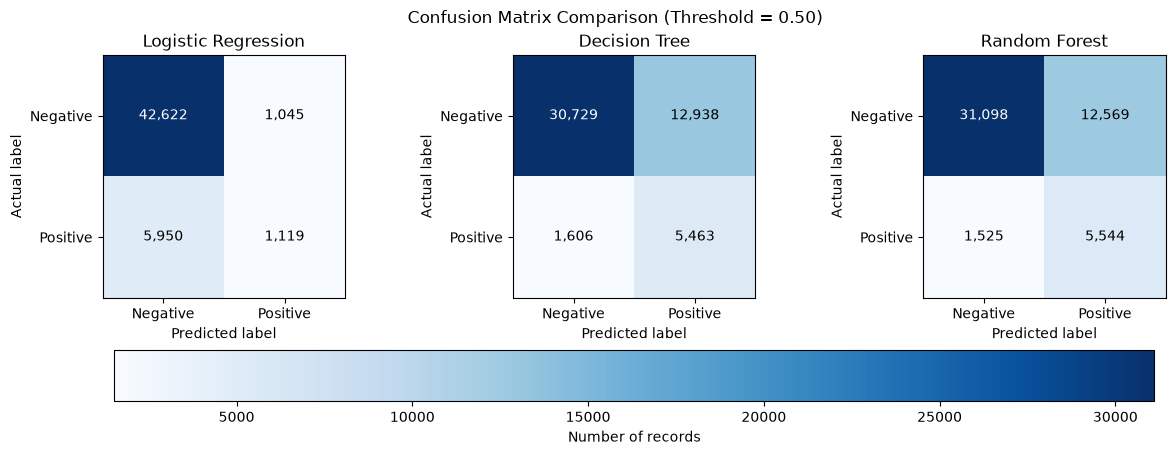

In [40]:
from sklearn.metrics import confusion_matrix

models = [
    ("Logistic Regression", logistic_model),
    ("Decision Tree", tree_model),
    ("Random Forest", forest_model)
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (name, model) in zip(axes, models):
    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )

    im = ax.imshow(cm, cmap="Blues")

    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    ax.set_xticks([0, 1], ["Negative", "Positive"])
    ax.set_yticks([0, 1], ["Negative", "Positive"])

    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, f"{cm[i, j]:,}",
                ha="center",
                va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black"
            )

fig.colorbar(im, ax=axes, location = "bottom", label="Number of records")
fig.suptitle("Confusion Matrix Comparison (Threshold = 0.50)")
constrained_layout=True
plt.show()

## Identify the most important patient features

In [41]:
# Extract feature importance from the trained Random Forest
importance_values = forest_model.feature_importances_

# Associate each importance value with its feature name
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance_values
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15).to_string(index=False))

             Feature  Importance
             GenHlth    0.239986
              HighBP    0.224551
                 BMI    0.142231
                 Age    0.098215
            HighChol    0.098000
            DiffWalk    0.055158
              Income    0.030134
            PhysHlth    0.025517
HeartDiseaseorAttack    0.024680
           Education    0.010569
        PhysActivity    0.008537
                 Sex    0.008489
            MentHlth    0.007163
   HvyAlcoholConsump    0.007010
           CholCheck    0.005431


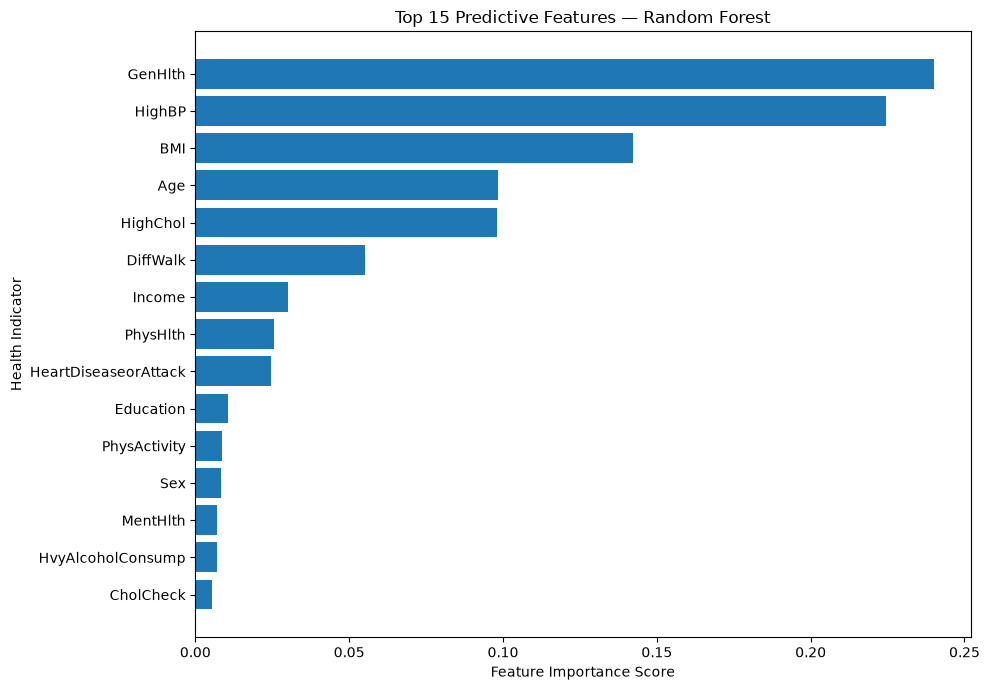

In [42]:
top_features = feature_importance.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Predictive Features — Random Forest")
plt.xlabel("Feature Importance Score")
plt.ylabel("Health Indicator")

plt.tight_layout()
plt.show()

## Design the patient risk-stratification system

In [43]:
# Generate risk categories

# Obtain class-1 probabilities from the trained Random Forest
rf_probabilities = forest_model.predict_proba(X_test)[:, 1]

# Define experimental risk categories
risk_categories = np.select(
    [
        rf_probabilities < 0.20,
        rf_probabilities < 0.50
    ],
    [
        "Lower",
        "Moderate"
    ],
    default="Higher"
)

# Create a results table
risk_results = pd.DataFrame({
    "Actual_Status": y_test.to_numpy(),
    "Predicted_Probability": rf_probabilities,
    "Risk_Category": risk_categories
})

print(risk_results.head(10))

   Actual_Status  Predicted_Probability Risk_Category
0            0.0               0.542205        Higher
1            1.0               0.753305        Higher
2            0.0               0.049650         Lower
3            0.0               0.123688         Lower
4            1.0               0.728297        Higher
5            0.0               0.510122        Higher
6            0.0               0.134322         Lower
7            0.0               0.045441         Lower
8            0.0               0.188057         Lower
9            0.0               0.646902        Higher


Risk_Category
Lower       16419
Moderate    16204
Higher      18113
Name: count, dtype: int64


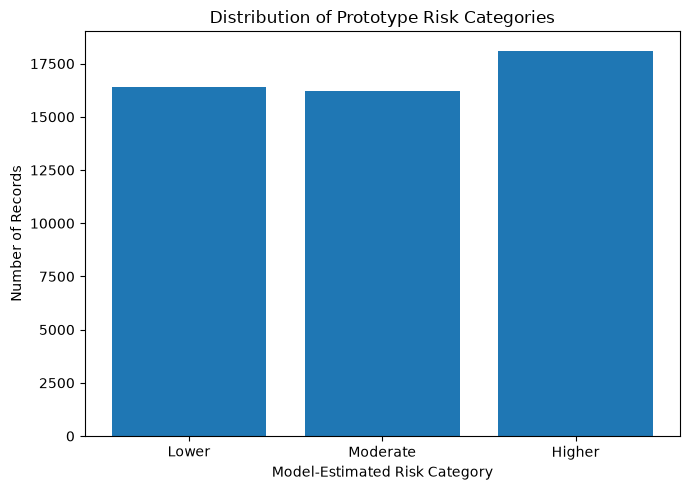

In [44]:
# Examine the distribution of categories
category_counts = (
    risk_results["Risk_Category"]
    .value_counts()
    .reindex(["Lower", "Moderate", "Higher"], fill_value=0)
)

print(category_counts)

plt.figure(figsize=(7, 5))
plt.bar(category_counts.index, category_counts.values)

plt.title("Distribution of Prototype Risk Categories")
plt.xlabel("Model-Estimated Risk Category")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

In [45]:
# Analyze the categories against actual labels

category_analysis = pd.crosstab(
    risk_results["Risk_Category"],
    risk_results["Actual_Status"],
    normalize="index"
) * 100

category_analysis = category_analysis.reindex(
    ["Lower", "Moderate", "Higher"]
)

print(category_analysis.round(2))

Actual_Status    0.0    1.0
Risk_Category              
Lower          98.59   1.41
Moderate       92.01   7.99
Higher         69.39  30.61


## Evaluate how well the categories identify status 1

In [46]:
# Count actual status 0 and status 1 records in each category
category_counts = pd.crosstab(
    risk_results["Risk_Category"],
    risk_results["Actual_Status"]
).reindex(["Lower", "Moderate", "Higher"])

print("Number of records by category and actual status:")
print(category_counts)

# Calculate each category's share of all status-1 records
status1_distribution = (
    category_counts[1.0] / category_counts[1.0].sum()
) * 100

print("\nDistribution of all status-1 records across categories:")
print(status1_distribution.round(2))

Number of records by category and actual status:
Actual_Status    0.0   1.0
Risk_Category             
Lower          16188   231
Moderate       14910  1294
Higher         12569  5544

Distribution of all status-1 records across categories:
Risk_Category
Lower        3.27
Moderate    18.31
Higher      78.43
Name: 1.0, dtype: float64


## final comparison of the four model configurations

In [47]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Class-Weighted Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Threshold": [0.50, 0.60, 0.50, 0.50],
    "Accuracy": [0.8621, 0.7864, 0.7133, 0.7222],
    "Precision": [0.5171, 0.3545, 0.2969, 0.3061],
    "Recall": [0.1583, 0.6492, 0.7728, 0.7843],
    "F1_Score": [0.2424, 0.4586, 0.4290, 0.4403],
    "ROC_AUC": [0.8192, 0.8196, 0.8140, 0.8237]
})

model_comparison = model_comparison.sort_values(
    by="F1_Score",
    ascending=False
).reset_index(drop=True)

print(model_comparison.round(4).to_string(index=False))

                             Model  Threshold  Accuracy  Precision  Recall  F1_Score  ROC_AUC
Class-Weighted Logistic Regression        0.6    0.7864     0.3545  0.6492    0.4586   0.8196
                     Random Forest        0.5    0.7222     0.3061  0.7843    0.4403   0.8237
                     Decision Tree        0.5    0.7133     0.2969  0.7728    0.4290   0.8140
               Logistic Regression        0.5    0.8621     0.5171  0.1583    0.2424   0.8192


In [48]:
# The model selection is based on the current evaluation results, not on clinical validation. 
# If the project's main priority is catching as many status-1 records as possible, Random Forest may be preferable.
# If the objective is to balance precision and recall, class-weighted Logistic Regression is the stronger choice by F1-score.

In [49]:
import joblib

joblib.dump(forest_model, "random_forest_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [54]:
print(X.columns.tolist())
print("\nNumber of features:", len(X.columns))

['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

Number of features: 21
